# Steering robustness: write orthogonalization + dose response

Both drawn from committed artifacts: `analysis/steering_orth_variants.json`
(regenerate with `python analysis/steering_orth_variants.py`; 27 records over
27 runs) and `experiments/fig17_dose_response/dose_response.{json,npz}`
(regenerate with `python experiments/fig17_dose_response/dose_response.py`;
10 runs, λ ∈ [0,1] in eighths).


In [1]:
import os, sys
from pathlib import Path

REPO = Path.cwd().resolve()
if not (REPO / 'plotting').is_dir():
    REPO = REPO.parent          # launched from notebooks/
assert (REPO / 'plotting').is_dir(), REPO
sys.path.insert(0, str(REPO))

# Point FACTORED_REPS_DATA at the directory holding experiments/<figure>/runs/<run>/
# {checkpoints,mlruns} (default: this repo). Must be set BEFORE this import.
import fwh_core, plotting.lib.runs as runs
assert Path(fwh_core.__file__).is_relative_to(REPO), 'fwh_core resolves outside this repo'
FIG = Path(os.path.relpath(REPO / 'figures')); FIG.mkdir(exist_ok=True)
ANALYSIS = REPO / 'analysis'
from IPython.display import Image, display
def show(*names, width=820):
    for n in names:
        print(n)
        display(Image(filename=FIG / f'{n}.png', width=width))


## Write-orthogonalization comparison


wrote ../figures/figure_orth_comparison.png (+.pdf)
figure_orth_comparison


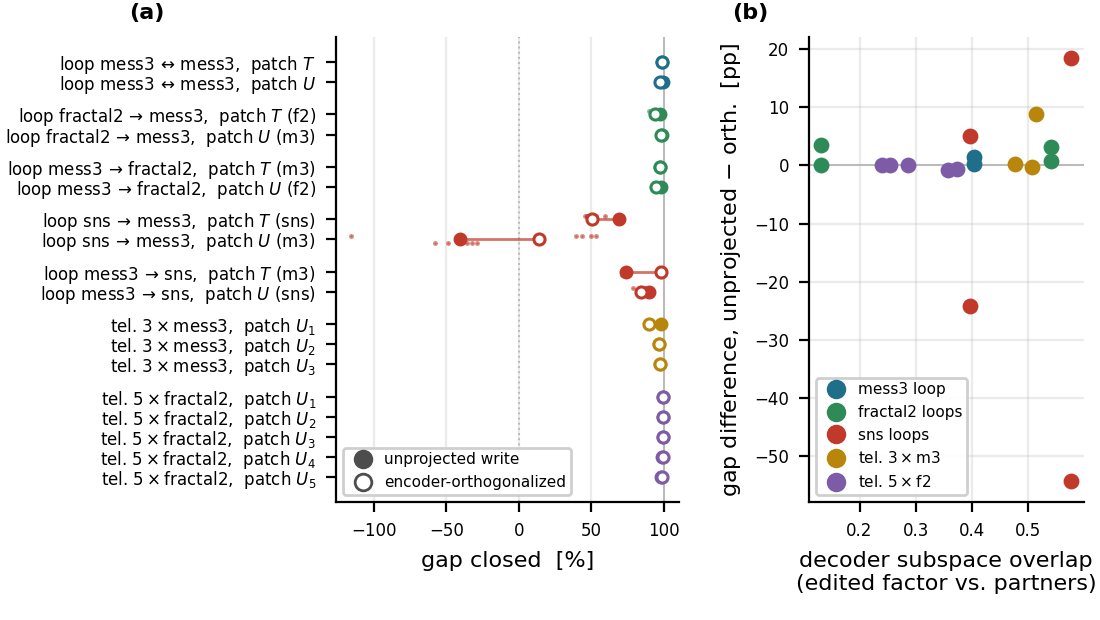

In [2]:
from plotting.orth_comparison import make_figure as make_orth

make_orth(FIG)
show('figure_orth_comparison', width=880)


## Dose response


.5) 3.02e-03 ( 64.8x floor)  on-path(1.0) 4.30e-03 ( 92.5x)  nearest ref at 0.5 is  16.4x the on-path KL
  loop_mess3_fractal2  f1  n=3603  floor 5.07e-05  on-path(0.5) 2.89e-04 (  5.7x floor)  on-path(1.0) 9.69e-04 ( 19.1x)  nearest ref at 0.5 is  56.1x the on-path KL
  loop_fractal2_mess3  f0  n=3660  floor 5.30e-05  on-path(0.5) 5.10e-04 (  9.6x floor)  on-path(1.0) 1.72e-03 ( 32.4x)  nearest ref at 0.5 is  28.8x the on-path KL
  loop_fractal2_mess3  f1  n=4786  floor 5.51e-05  on-path(0.5) 7.20e-04 ( 13.1x floor)  on-path(1.0) 1.59e-03 ( 28.8x)  nearest ref at 0.5 is  49.5x the on-path KL

figure_dose_response


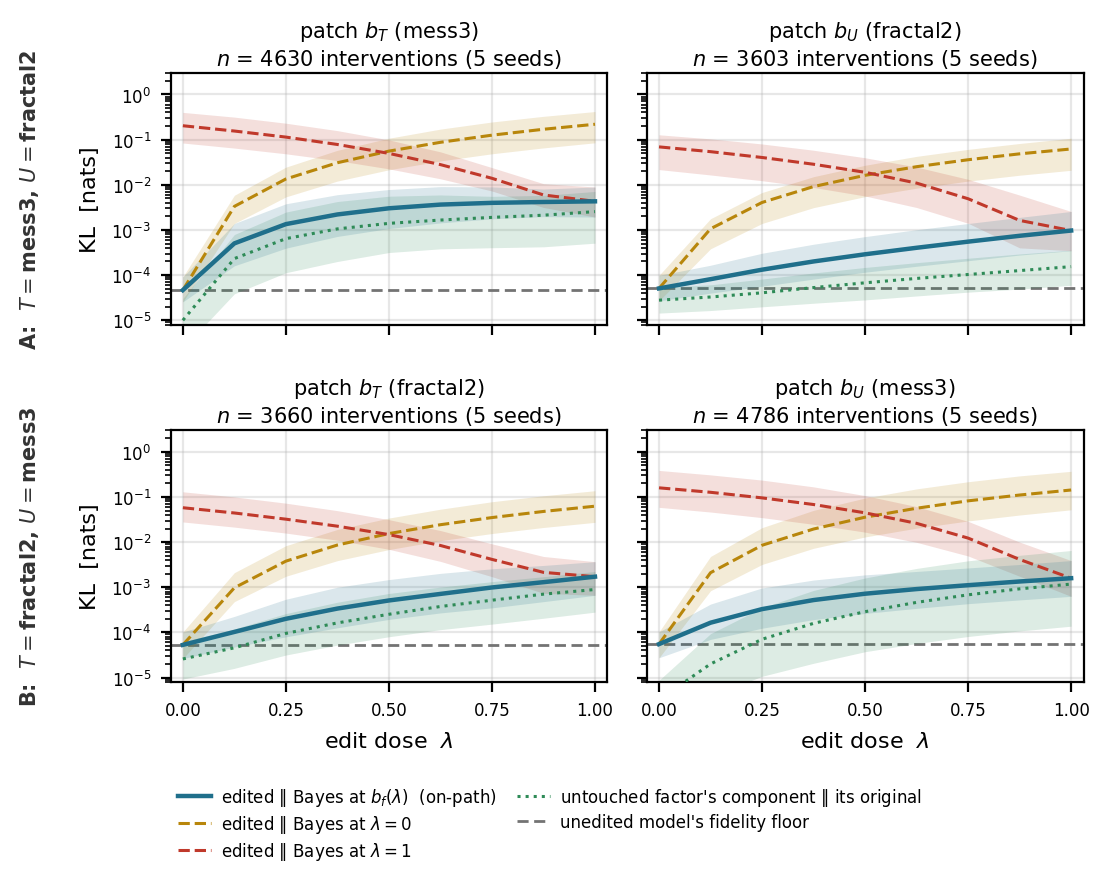

In [3]:
import subprocess
r = subprocess.run([sys.executable, 'experiments/fig17_dose_response/figure_dose_response.py',
                    '--out-dir', 'figures'],   # relative to cwd=REPO
                   cwd=REPO, capture_output=True, text=True)
print(r.stdout[-600:]); assert r.returncode == 0, r.stderr[-2000:]
show('figure_dose_response', width=760)
